# Lesson 15 — Model Validation

## Objective
Evaluate residual structure, lag-1 autocorrelation,
and breakpoint sensitivity for the three-segment
linear regression of the ODP Site 1262 δ13C record.

## Dataset
Barnet et al. (2019), PANGAEA
DOI: 10.1594/PANGAEA.903507

## Important limitations
The published age model is treated as fixed.
Residuals may be serially correlated.
The record contains irregular age spacing.
Statistical breakpoints are not necessarily geological boundaries.

Load the dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project directory
cwd = Path.cwd()

if (cwd / "data" / "raw").is_dir():
    root = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    root = cwd.parent
else:
    raise FileNotFoundError("Project data/raw folder not found.")

raw_file = root / "data" / "raw" / "208-1262_isotope.tab.tsv"

# Locate the end of the PANGAEA metadata
with raw_file.open("r", encoding="utf-8-sig") as f:
    lines = f.readlines()

metadata_end = next(
    i for i, line in enumerate(lines)
    if line.strip() == "*/"
)

df = pd.read_csv(
    raw_file,
    sep="\t",
    skiprows=metadata_end + 1
)

carbon_col = "δ13C bulk carb [‰ PDB]"
age_col = "Age [ka BP]"

df["age_ma"] = df[age_col] / 1000

analysis = (
    df.loc[
        df["age_ma"].between(55.65, 56.30),
        ["age_ma", carbon_col]
    ]
    .dropna()
    .sort_values("age_ma", ascending=False)
    .reset_index(drop=True)
)

x = analysis["age_ma"].to_numpy()
y = analysis[carbon_col].to_numpy()

n = len(y)

print("Number of observations:", n)

Number of observations: 247


Define the fitting function

In [2]:
def fit_segment(xs, ys):
    """Fit a straight line and return predictions and RSS."""

    if len(xs) < 2 or np.ptp(xs) == 0:
        raise ValueError("Insufficient distinct ages.")

    slope, intercept = np.polyfit(xs, ys, 1)
    predictions = slope * xs + intercept

    rss = np.sum((ys - predictions) ** 2)

    return {
        "slope": slope,
        "intercept": intercept,
        "predicted": predictions,
        "rss": rss
    }

Find the best three-segment linear model

In [3]:
def fit_three_segments(x, y, min_segment=15):

    n = len(y)

    # A boundary cannot split observations with the same age
    valid = {
        k for k in range(1, n)
        if x[k - 1] != x[k]
    }

    # Cache fits for intervals
    cache = {}

    def interval_fit(i, j):
        key = (i, j)

        if key not in cache:
            cache[key] = fit_segment(
                x[i:j], y[i:j]
            )

        return cache[key]

    best = {
        "rss": np.inf,
        "k1": None,
        "k2": None
    }

    for k1 in range(min_segment, n - 2 * min_segment + 1):

        if k1 not in valid:
            continue

        for k2 in range(k1 + min_segment, n - min_segment + 1):

            if k2 not in valid:
                continue

            total_rss = (
                interval_fit(0, k1)["rss"]
                + interval_fit(k1, k2)["rss"]
                + interval_fit(k2, n)["rss"]
            )

            if total_rss < best["rss"]:
                best = {
                    "rss": total_rss,
                    "k1": k1,
                    "k2": k2
                }

    if best["k1"] is None:
        raise ValueError("No valid segmentation found.")

    return best

In [4]:
best = fit_three_segments(x, y, min_segment=15)

k1 = best["k1"]
k2 = best["k2"]

print("Total RSS:", round(best["rss"], 4))
print("First boundary:", x[k1-1], "to", x[k1], "Ma")
print("Second boundary:", x[k2-1], "to", x[k2], "Ma")

Total RSS: 3.0375
First boundary: 55.932 to 55.905 Ma
Second boundary: 55.87 to 55.867 Ma


Generate model predictions

In [5]:
# Empty array to hold predictions
predicted = np.empty(n)

# Fit the three segments independently
for start, end in [
    (0, k1),
    (k1, k2),
    (k2, n)
]:
    fit = fit_segment(
        x[start:end],
        y[start:end]
    )

    predicted[start:end] = fit["predicted"]

# Calculate residuals
residuals = y - predicted

print("Mean residual:", residuals.mean())
print("Residual standard deviation:", residuals.std(ddof=1))
print("Maximum absolute residual:", np.abs(residuals).max())

Mean residual: -2.492742854237325e-14
Residual standard deviation: 0.11111970193378651
Maximum absolute residual: 0.4479893574932733


Plot residuals against age

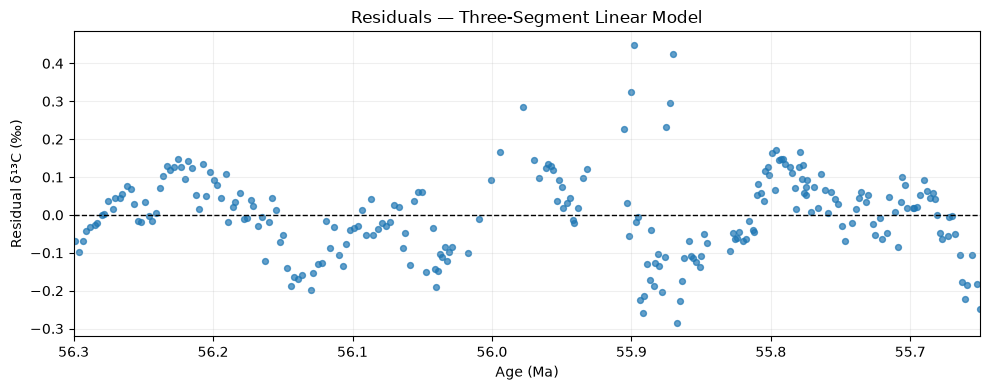

In [6]:
fig_resid, ax = plt.subplots(figsize=(10, 4))

ax.scatter(
    x,
    residuals,
    s=18,
    alpha=0.7
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlim(56.30, 55.65)
ax.set_xlabel("Age (Ma)")
ax.set_ylabel("Residual δ¹³C (‰)")
ax.set_title("Residuals — Three-Segment Linear Model")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Calculate lag-1 autocorrelation

In [7]:
lag1 = np.corrcoef(
    residuals[:-1],
    residuals[1:]
)[0, 1]

print(f"Lag-1 residual autocorrelation: {lag1:.3f}")

Lag-1 residual autocorrelation: 0.692


Calculate autocorrelation separately within segments

In [8]:
autocorrelation_results = []

for name, start, end in [
    ("Older", 0, k1),
    ("Middle", k1, k2),
    ("Younger", k2, n)
]:

    segment_residuals = residuals[start:end]

    if len(segment_residuals) >= 3:
        r = np.corrcoef(
            segment_residuals[:-1],
            segment_residuals[1:]
        )[0, 1]
    else:
        r = np.nan

    autocorrelation_results.append({
        "segment": name,
        "n": len(segment_residuals),
        "lag1_autocorrelation": r
    })

autocorrelation_table = pd.DataFrame(
    autocorrelation_results
)

display(autocorrelation_table)

,segment,n,lag1_autocorrelation
0,Older,125,0.799209
1,Middle,22,0.629189
2,Younger,100,0.864815


Repeat the regression using different minimum segment sizes

In [9]:
sensitivity_results = []

for minimum in [10, 15, 20, 25, 30]:

    result = fit_three_segments(
        x, y, min_segment=minimum
    )

    a = result["k1"]
    b = result["k2"]

    sensitivity_results.append({
        "min_segment": minimum,
        "rss": result["rss"],
        "first_older_ma": x[a - 1],
        "first_younger_ma": x[a],
        "second_older_ma": x[b - 1],
        "second_younger_ma": x[b]
    })

sensitivity_table = pd.DataFrame(
    sensitivity_results
)

display(sensitivity_table)

,min_segment,rss,first_older_ma,first_younger_ma,second_older_ma,second_younger_ma
0,10,3.037507,55.932,55.905,55.870,55.867
1,15,3.037507,55.932,55.905,55.870,55.867
2,20,3.037507,55.932,55.905,55.870,55.867
3,25,4.027855,55.932,55.905,55.864,55.862
4,30,4.481729,55.932,55.905,55.846,55.829


Plot the breakpoint sensitivity

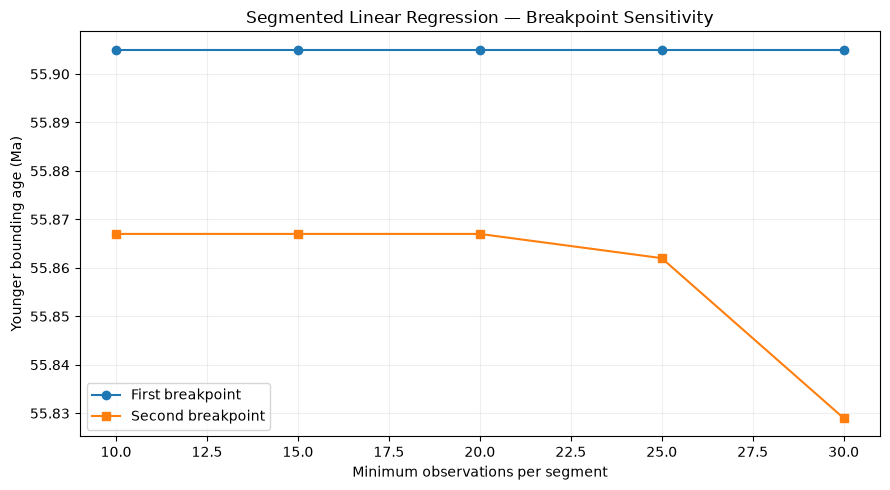

In [10]:
fig_sens, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    sensitivity_table["min_segment"],
    sensitivity_table["first_younger_ma"],
    marker="o",
    label="First breakpoint"
)

ax.plot(
    sensitivity_table["min_segment"],
    sensitivity_table["second_younger_ma"],
    marker="s",
    label="Second breakpoint"
)

ax.set_xlabel("Minimum observations per segment")
ax.set_ylabel("Younger bounding age (Ma)")
ax.set_title("Segmented Linear Regression — Breakpoint Sensitivity")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Check whether the fitted boundaries coincide with the gap

In [11]:
gap_start = 55.932
gap_end = 55.905

boundary_table = pd.DataFrame({
    "boundary": ["First", "Second"],
    "older_ma": [x[k1-1], x[k2-1]],
    "younger_ma": [x[k1], x[k2]]
})

boundary_table["gap_kyr"] = (
    boundary_table["older_ma"]
    - boundary_table["younger_ma"]
) * 1000

display(boundary_table)

,boundary,older_ma,younger_ma,gap_kyr
0,First,55.932,55.905,27.0
1,Second,55.870,55.867,3.0


Export tables and figures

In [12]:
results_dir = root / "results"
figure_dir = root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

autocorrelation_table.to_csv(
    results_dir / "residual_autocorrelation.csv",
    index=False
)

sensitivity_table.to_csv(
    results_dir / "linear_breakpoint_sensitivity.csv",
    index=False
)

boundary_table.to_csv(
    results_dir / "linear_boundary_gap_summary.csv",
    index=False
)

fig_resid.savefig(
    figure_dir / "segmented_linear_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

fig_sens.savefig(
    figure_dir / "linear_breakpoint_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

print("Lesson 15 validation results saved successfully.")

Lesson 15 validation results saved successfully.


## Statistical validation of segmented linear regression

The three-segment piecewise-linear model was evaluated using residual diagnostics and sensitivity analysis.

Model residuals were calculated as the differences between observed and fitted bulk carbonate δ¹³C values. Residual distributions were examined visually to identify systematic patterns, changes in variability, and possible departures from the assumed linear trends.

Lag-1 residual autocorrelation was calculated for the full ordered record and separately within the fitted segments. These statistics were treated as exploratory measures of serial dependence because the observations are irregularly spaced in geological time.

Breakpoint sensitivity was evaluated by repeating the regression with minimum segment sizes of 10, 15, 20, 25, and 30 observations. The resulting breakpoint intervals and residual sums of squares were compared to assess stability under alternative segmentation constraints.

The relationship between the fitted boundaries and the previously identified 27 kyr sampling gap was also examined.

The analysis does not explicitly incorporate analytical uncertainty, continuous-time autocorrelation, or age-model uncertainty. Consequently, the fitted slopes and breakpoints are interpreted as descriptive statistical characteristics of the sampled isotope record rather than definitive estimates of instantaneous carbon-cycle rates or geological event boundaries.